Exploratory Data Analysis - EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel(r"D:\Guvi\Project 2 Agriculture\clean_agri_data.xlsx")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16146 entries, 0 to 16145
Data columns (total 80 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   DIST_CODE                                  16146 non-null  int64  
 1   YEAR                                       16146 non-null  int64  
 2   STATE_CODE                                 16146 non-null  int64  
 3   STATE_NAME                                 16146 non-null  str    
 4   DIST_NAME                                  16146 non-null  str    
 5   RICE_AREA_1000_HA                          16146 non-null  float64
 6   RICE_PRODUCTION_1000_TONS                  16146 non-null  float64
 7   RICE_YIELD_KG_PER_HA                       16146 non-null  float64
 8   WHEAT_AREA_1000_HA                         16146 non-null  float64
 9   WHEAT_PRODUCTION_1000_TONS                 16146 non-null  float64
 10  WHEAT_YIELD_KG_PER_HA            

1. Top 7 Rice Producing States

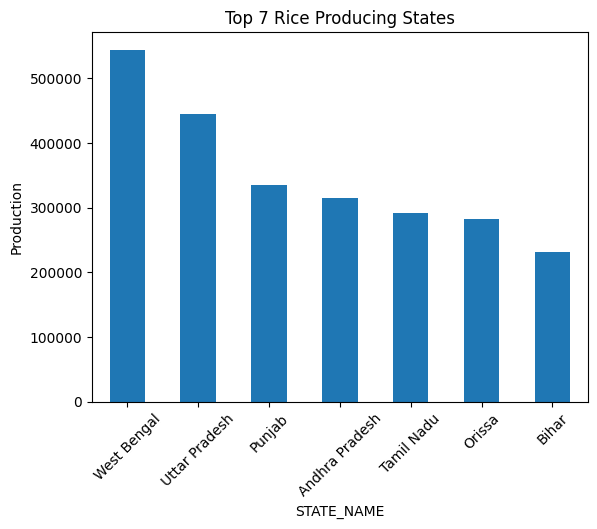

In [4]:
rice_prod = df.groupby("STATE_NAME")["RICE_PRODUCTION_1000_TONS"].sum().sort_values(ascending=False).head(7)

plt.figure()
rice_prod.plot(kind='bar')
plt.title("Top 7 Rice Producing States")
plt.ylabel("Production")
plt.xticks(rotation=45)
plt.show()

2. Top 5 Wheat Producing States

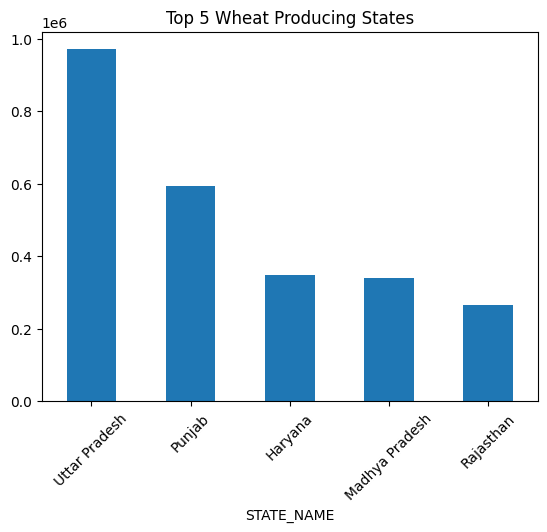

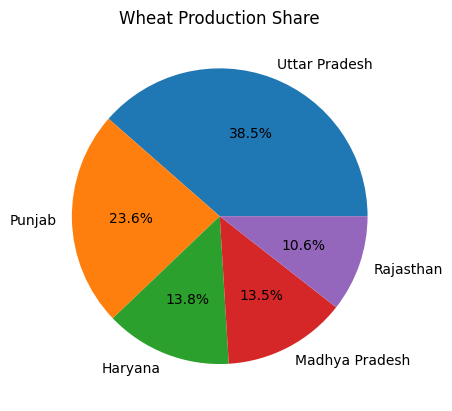

In [5]:
wheat_prod = df.groupby("STATE_NAME")["WHEAT_PRODUCTION_1000_TONS"].sum().sort_values(ascending=False).head(5)

# Bar chart
plt.figure()
wheat_prod.plot(kind='bar')
plt.title("Top 5 Wheat Producing States")
plt.xticks(rotation=45)
plt.show()

# Pie chart
plt.figure()
wheat_prod.plot(kind='pie', autopct='%1.1f%%')
plt.title("Wheat Production Share")
plt.ylabel("")
plt.show()

3. Oilseed Production by Top 5 States

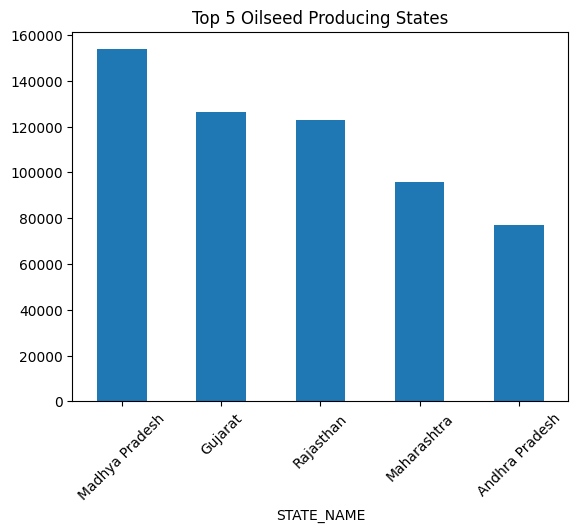

In [6]:
oilseed = df.groupby("STATE_NAME")["OILSEEDS_PRODUCTION_1000_TONS"].sum().sort_values(ascending=False).head(5)

plt.figure()
oilseed.plot(kind='bar')
plt.title("Top 5 Oilseed Producing States")
plt.xticks(rotation=45)
plt.show()

4. Top 7 Sunflower Producing States

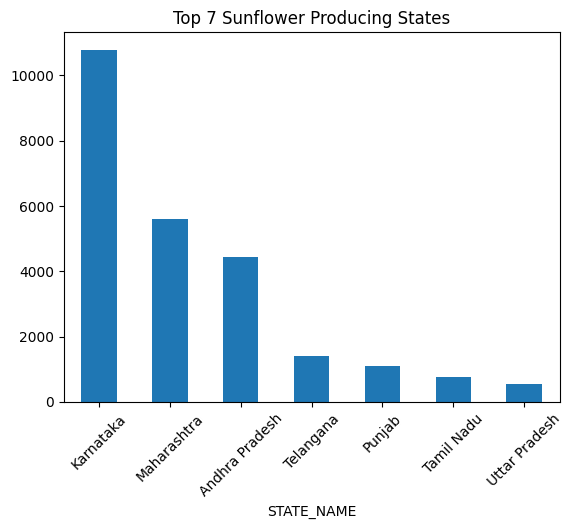

In [7]:
sunflower = df.groupby("STATE_NAME")["SUNFLOWER_PRODUCTION_1000_TONS"].sum().sort_values(ascending=False).head(7)

plt.figure()
sunflower.plot(kind='bar')
plt.title("Top 7 Sunflower Producing States")
plt.xticks(rotation=45)
plt.show()

5. Sugarcane Production Over Years

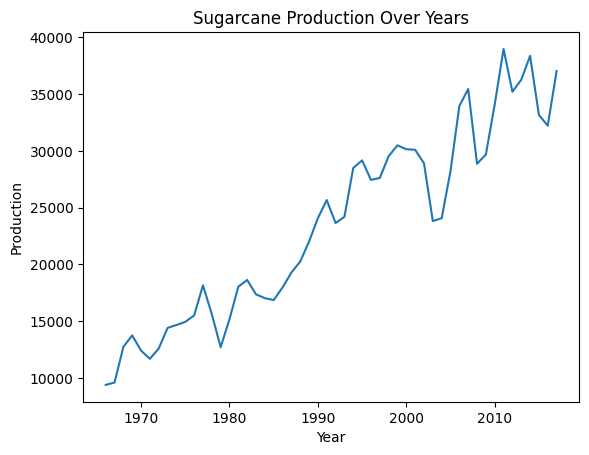

In [8]:
sugarcane_trend = df.groupby("YEAR")["SUGARCANE_PRODUCTION_1000_TONS"].sum()

plt.figure()
sugarcane_trend.plot()
plt.title("Sugarcane Production Over Years")
plt.xlabel("Year")
plt.ylabel("Production")
plt.show()

6. Rice vs Wheat Production

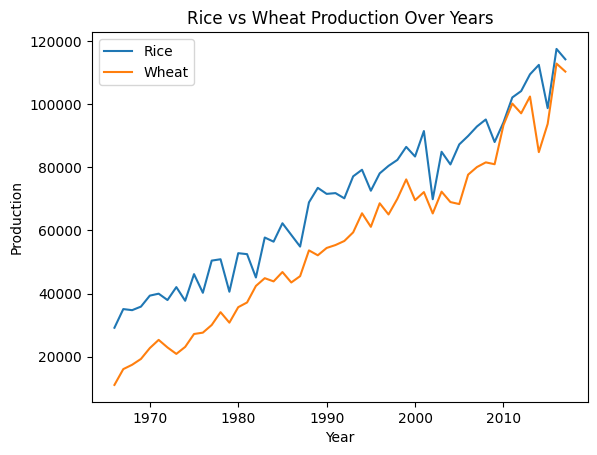

In [9]:
rice_year = df.groupby("YEAR")["RICE_PRODUCTION_1000_TONS"].sum()
wheat_year = df.groupby("YEAR")["WHEAT_PRODUCTION_1000_TONS"].sum()

plt.figure()
plt.plot(rice_year, label="Rice")
plt.plot(wheat_year, label="Wheat")
plt.legend()
plt.title("Rice vs Wheat Production Over Years")
plt.xlabel("Year")
plt.ylabel("Production")
plt.show()

7. Rice Production by West Bengal Districts

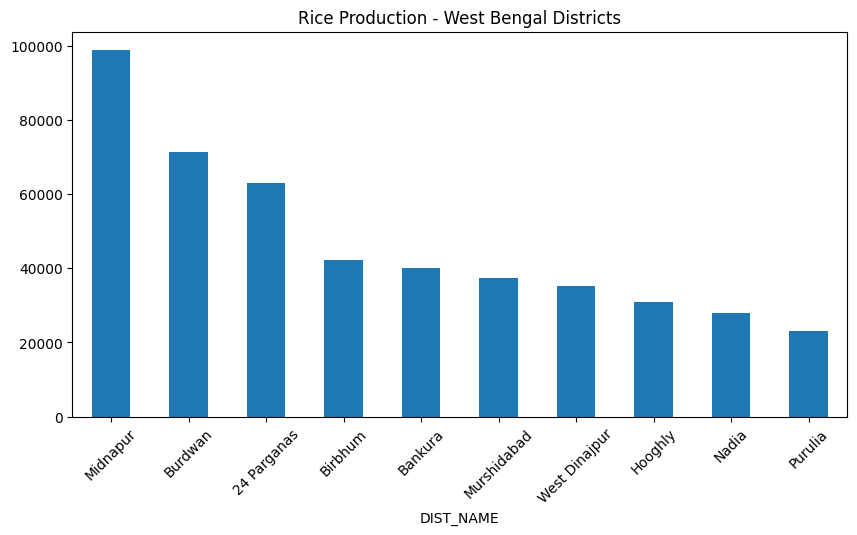

In [10]:
wb = df[df["STATE_NAME"] == "West Bengal"]
wb_rice = wb.groupby("DIST_NAME")["RICE_PRODUCTION_1000_TONS"].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))
wb_rice.head(10).plot(kind='bar')
plt.title("Rice Production - West Bengal Districts")
plt.xticks(rotation=45)
plt.show()

8. Top 10 Wheat Production Years from UP

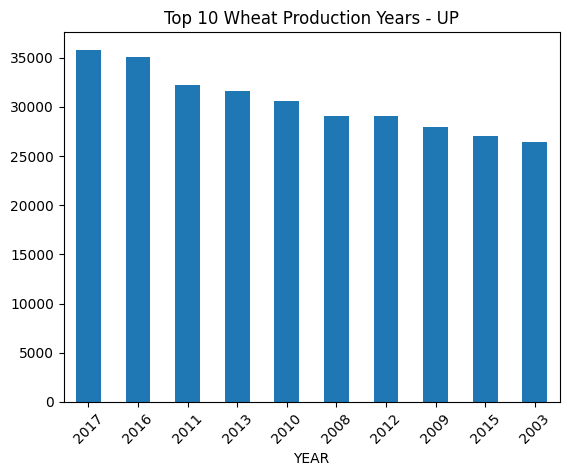

In [11]:
up = df[df["STATE_NAME"] == "Uttar Pradesh"]
up_wheat = up.groupby("YEAR")["WHEAT_PRODUCTION_1000_TONS"].sum().sort_values(ascending=False).head(10)

plt.figure()
up_wheat.plot(kind='bar')
plt.title("Top 10 Wheat Production Years - UP")
plt.xticks(rotation=45)
plt.show()

9. Millet Production Over Years

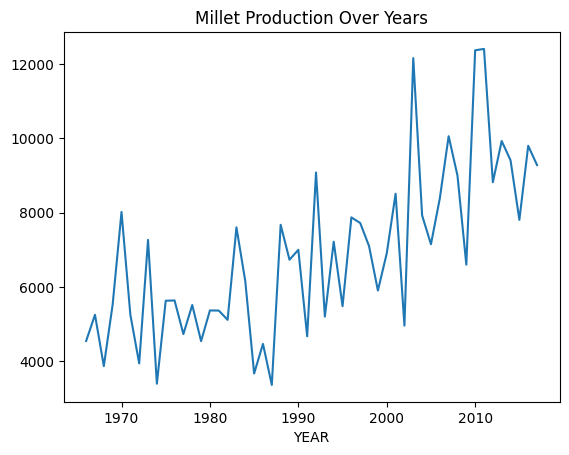

In [12]:
millet = df.groupby("YEAR")["PEARL_MILLET_PRODUCTION_1000_TONS"].sum()

plt.figure()
millet.plot()
plt.title("Millet Production Over Years")
plt.show()

10. Sorghum Production

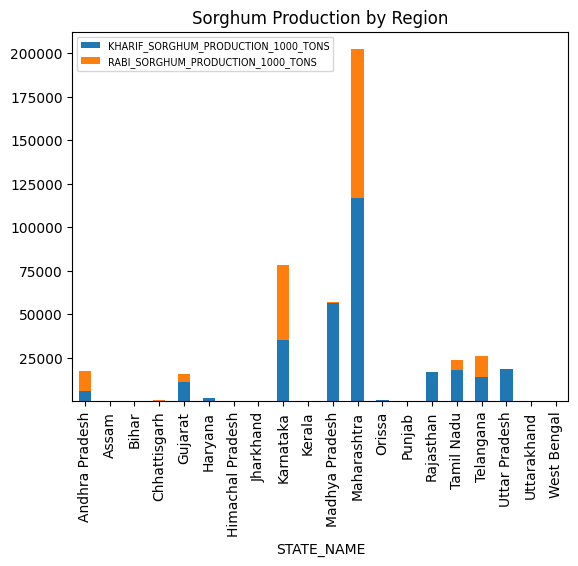

In [13]:
sorghum = df.groupby("STATE_NAME")[["KHARIF_SORGHUM_PRODUCTION_1000_TONS","RABI_SORGHUM_PRODUCTION_1000_TONS"]].sum()

sorghum.plot(kind='bar', stacked=True)
plt.title("Sorghum Production by Region")
plt.xticks(rotation=90)
plt.legend(loc='best',fontsize='x-small')
plt.show()

11. Top 7 States for Groundnut Production

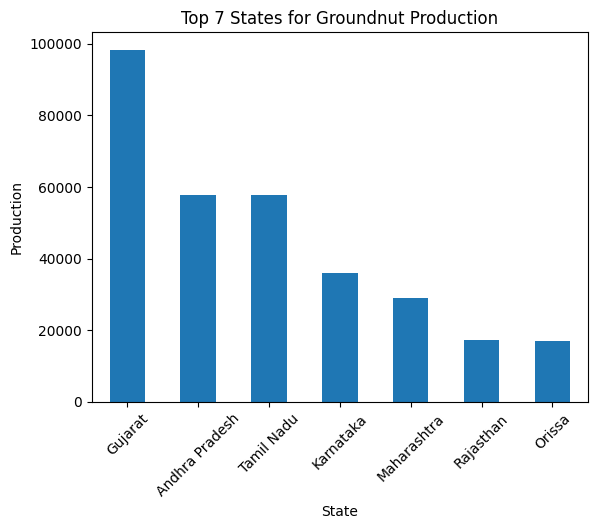

In [14]:
groundnut = df.groupby("STATE_NAME")["GROUNDNUT_PRODUCTION_1000_TONS"].sum().sort_values(ascending=False).head(7)

plt.figure()
groundnut.plot(kind='bar')
plt.title("Top 7 States for Groundnut Production")
plt.xlabel("State")
plt.ylabel("Production")
plt.xticks(rotation=45)
plt.show()

12. Soybean Production by Top 5 States & Yield Efficiency

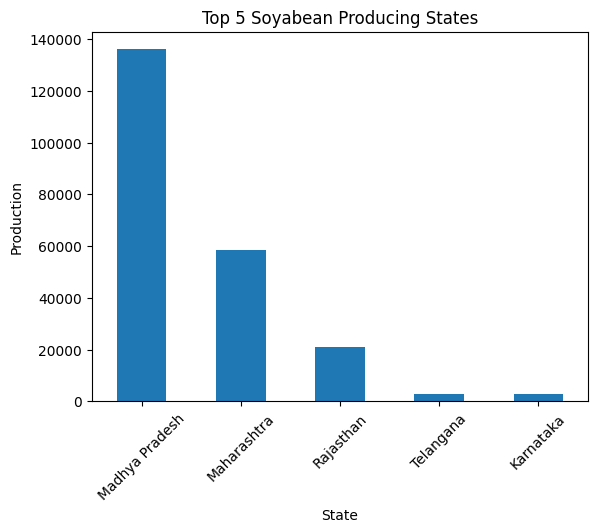

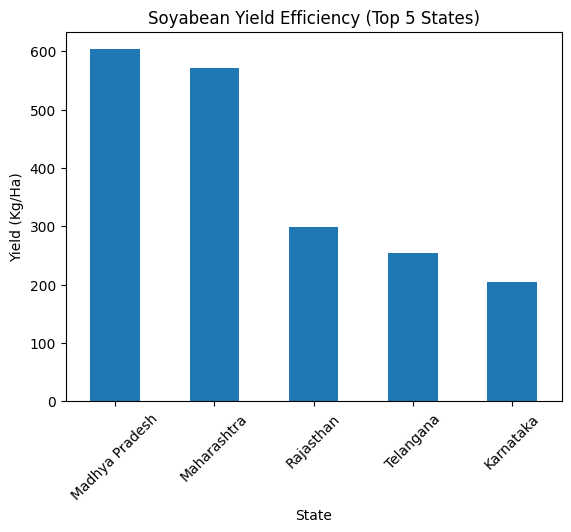

In [15]:
soyabean = df.groupby("STATE_NAME").agg({
    "SOYABEAN_PRODUCTION_1000_TONS": "sum",
    "SOYABEAN_YIELD_KG_PER_HA": "mean"
})

# Get top 5 states by production
top5_soyabean = soyabean.sort_values("SOYABEAN_PRODUCTION_1000_TONS", ascending=False).head(5)

# Production Plot
plt.figure()
top5_soyabean["SOYABEAN_PRODUCTION_1000_TONS"].plot(kind='bar')
plt.title("Top 5 Soyabean Producing States")
plt.xlabel("State")
plt.ylabel("Production")
plt.xticks(rotation=45)
plt.show()

# Yield Efficiency Plot
plt.figure()
top5_soyabean["SOYABEAN_YIELD_KG_PER_HA"].plot(kind='bar')
plt.title("Soyabean Yield Efficiency (Top 5 States)")
plt.xlabel("State")
plt.ylabel("Yield (Kg/Ha)")
plt.xticks(rotation=45)
plt.show()

13. Oilseed Production in Major States

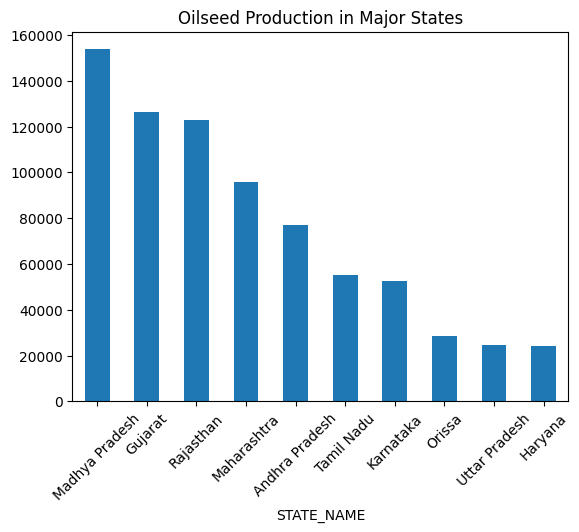

In [16]:
oilseed_major = df.groupby("STATE_NAME")["OILSEEDS_PRODUCTION_1000_TONS"].sum().sort_values(ascending=False).head(10)

plt.figure()
oilseed_major.plot(kind='bar')
plt.title("Oilseed Production in Major States")
plt.xticks(rotation=45)
plt.show()

14. Impact of Area Cultivated on Production (Rice, Wheat, Maize)

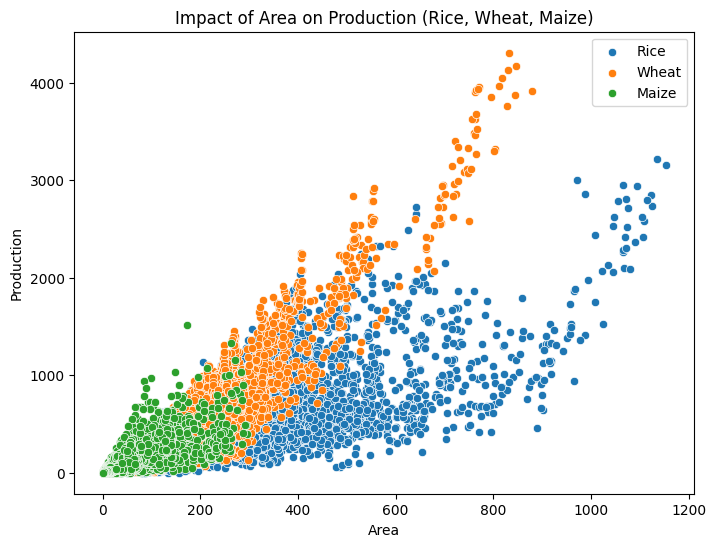

In [17]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x=df["RICE_AREA_1000_HA"],
    y=df["RICE_PRODUCTION_1000_TONS"],
    label="Rice"
)

sns.scatterplot(
    x=df["WHEAT_AREA_1000_HA"],
    y=df["WHEAT_PRODUCTION_1000_TONS"],
    label="Wheat"
)

sns.scatterplot(
    x=df["MAIZE_AREA_1000_HA"],
    y=df["MAIZE_PRODUCTION_1000_TONS"],
    label="Maize"
)

plt.legend()
plt.title("Impact of Area on Production (Rice, Wheat, Maize)")
plt.xlabel("Area")
plt.ylabel("Production")
plt.show()

15. Rice vs. Wheat Yield Across States

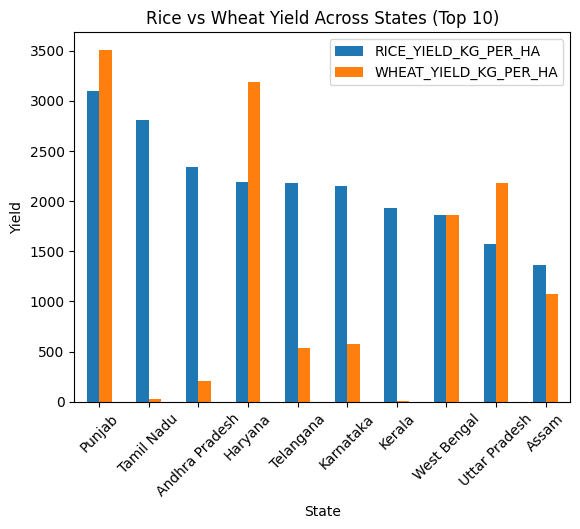

In [18]:
yield_compare = df.groupby("STATE_NAME").agg({
    "RICE_YIELD_KG_PER_HA": "mean",
    "WHEAT_YIELD_KG_PER_HA": "mean"
}).sort_values("RICE_YIELD_KG_PER_HA", ascending=False)

# Plot
yield_compare.head(10).plot(kind='bar')

plt.title("Rice vs Wheat Yield Across States (Top 10)")
plt.xlabel("State")
plt.ylabel("Yield")
plt.xticks(rotation=45)
plt.show()